In [50]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("compas-scores-two-years.csv")

features = [
    "age",
    "priors_count",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "c_charge_degree",
]
interesting_features = [
    "sex", "age", "race", 
    "juv_fel_count", 
    "juv_misd_count", 
    "juv_other_count", 
    "priors_count", 
    "c_charge_degree", 
    "c_charge_desc"
]

X = df[features].copy()
y = df["two_year_recid"]

X["c_charge_degree"] = X["c_charge_degree"].map({"F": 1, "M": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67, stratify=y 
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.1%}")

Test accuracy: 67.5%


In [51]:
results = pd.DataFrame({
    "race": df.loc[X_test.index, "race"],
    "sex": df.loc[X_test.index, "sex"],
    "age": df.loc[X_test.index, "age_cat"],
    "actual": y_test,
    "predicted": y_pred,
})

no_new_case = results[results["actual"] == 0]
new_case = results[results["actual"] == 1]
TFPN_names = ["False Positive", "True Negative", "True Positive", "False Negative"]
TFPN_counts = {
    "Race: African-American": [0, 0, 0, 0],
    "Race: Asian": [0, 0, 0, 0],
    "Race: Caucasian": [0, 0, 0, 0],
    "Race: Hispanic": [0, 0, 0, 0],
    "Race: Native American": [0, 0, 0, 0],
    "Race: Other": [0, 0, 0, 0],
    "Sex: Male": [0, 0, 0, 0],
    "Sex: Female": [0, 0, 0, 0],
    "Age: Less than 25": [0, 0, 0, 0],
    "Age: 25 - 45": [0, 0, 0, 0],
    "Age: Greater than 45": [0, 0, 0, 0]
}

# FPR race
print("False Positive Rate (FPR) by race:")
for group in ["African-American", "Asian", "Caucasian", "Hispanic", "Native American", "Other"]:
    group_rows = no_new_case[no_new_case["race"] == group]

    false_positives = (group_rows["predicted"] == 1).sum()
    total = len(group_rows)
    false_positive_rate = false_positives / total
    TFPN_counts[f"Race: {group}"][0] = false_positives
    TFPN_counts[f"Race: {group}"][1] = total - false_positives
    
    print(f"{group} FPR: {false_positives}/{total} = {false_positive_rate:.1%}")

# FPR sex
print("\nFalse Positive Rate (FPR) by sex:")
for group in ["Male", "Female"]:
    group_rows = results[results["sex"] == group]

    false_positives = (group_rows["predicted"] == 1).sum()
    total = len(group_rows)
    false_positive_rate = false_positives / total
    TFPN_counts[f"Sex: {group}"][0] = false_positives
    TFPN_counts[f"Sex: {group}"][1] = total - false_positives

    print(f"{group} FPR: {false_positives}/{total} = {false_positive_rate:.1%}")

# FPR age
print("\nFalse Positive Rate (FPR) by age:")
for group in ["Less than 25", "25 - 45", "Greater than 45"]:
    group_rows = results[results["age"] == group]

    false_positives = (group_rows["predicted"] == 1).sum()
    total = len(group_rows)
    false_positive_rate = false_positives / total
    TFPN_counts[f"Age: {group}"][0] = false_positives
    TFPN_counts[f"Age: {group}"][1] = total - false_positives

    print(f"{group} FPR: {false_positives}/{total} = {false_positive_rate:.1%}")

# FNR race
print("\nFalse Negative Rate (FNR) by race:")
for group in ["African-American", "Asian", "Caucasian", "Hispanic", "Native American", "Other"]:
    group_rows = new_case[new_case["race"] == group]

    false_negatives = (group_rows["predicted"] == 0).sum()
    total = len(group_rows)
    false_negative_rate = false_negatives / total
    TFPN_counts[f"Race: {group}"][2] = total - false_negatives
    TFPN_counts[f"Race: {group}"][3] = false_negatives
    
    print(f"{group} FNR: {false_negatives}/{total} = {false_negative_rate:.1%}")
    
# FNR sex
print("\nFalse Negative Rate (FNR) by sex:")
for group in ["Male", "Female"]:
    group_rows = results[results["sex"] == group]

    false_negatives = (group_rows["predicted"] == 0).sum()
    total = len(group_rows)
    false_negative_rate = false_negatives / total
    TFPN_counts[f"Sex: {group}"][2] = total - false_negatives
    TFPN_counts[f"Sex: {group}"][3] = false_negatives

    print(f"{group} FNR: {false_negatives}/{total} = {false_negative_rate:.1%}")

# FNR age
print("\nFalse Negative Rate (FNR) by age:")
for group in ["Less than 25", "25 - 45", "Greater than 45"]:
    group_rows = results[results["age"] == group]

    false_negatives = (group_rows["predicted"] == 0).sum()
    total = len(group_rows)
    false_negative_rate = false_negatives / total
    TFPN_counts[f"Age: {group}"][2] = total - false_negatives
    TFPN_counts[f"Age: {group}"][3] = false_negatives

    print(f"{group} FNR: {false_negatives}/{total} = {false_negative_rate:.1%}")

False Positive Rate (FPR) by race:
African-American FPR: 92/369 = 24.9%
Asian FPR: 0/5 = 0.0%
Caucasian FPR: 23/286 = 8.0%
Hispanic FPR: 13/80 = 16.2%
Native American FPR: 0/0 = nan%
Other FPR: 2/53 = 3.8%

False Positive Rate (FPR) by sex:
Male FPR: 380/1153 = 33.0%
Female FPR: 61/290 = 21.0%

False Positive Rate (FPR) by age:
Less than 25 FPR: 119/306 = 38.9%
25 - 45 FPR: 278/821 = 33.9%
Greater than 45 FPR: 44/316 = 13.9%

False Negative Rate (FNR) by race:
African-American FNR: 151/360 = 41.9%
Asian FNR: 1/2 = 50.0%
Caucasian FNR: 128/199 = 64.3%
Hispanic FNR: 34/54 = 63.0%
Native American FNR: 1/3 = 33.3%
Other FNR: 24/32 = 75.0%

False Negative Rate (FNR) by sex:
Male FNR: 773/1153 = 67.0%
Female FNR: 229/290 = 79.0%

False Negative Rate (FNR) by age:
Less than 25 FNR: 187/306 = 61.1%
25 - 45 FNR: 543/821 = 66.1%
Greater than 45 FNR: 272/316 = 86.1%


C:\Users\henry\AppData\Local\Temp\ipykernel_2308\1803218594.py:33: RuntimeWarning: invalid value encountered in scalar divide
  false_positive_rate = false_positives / total


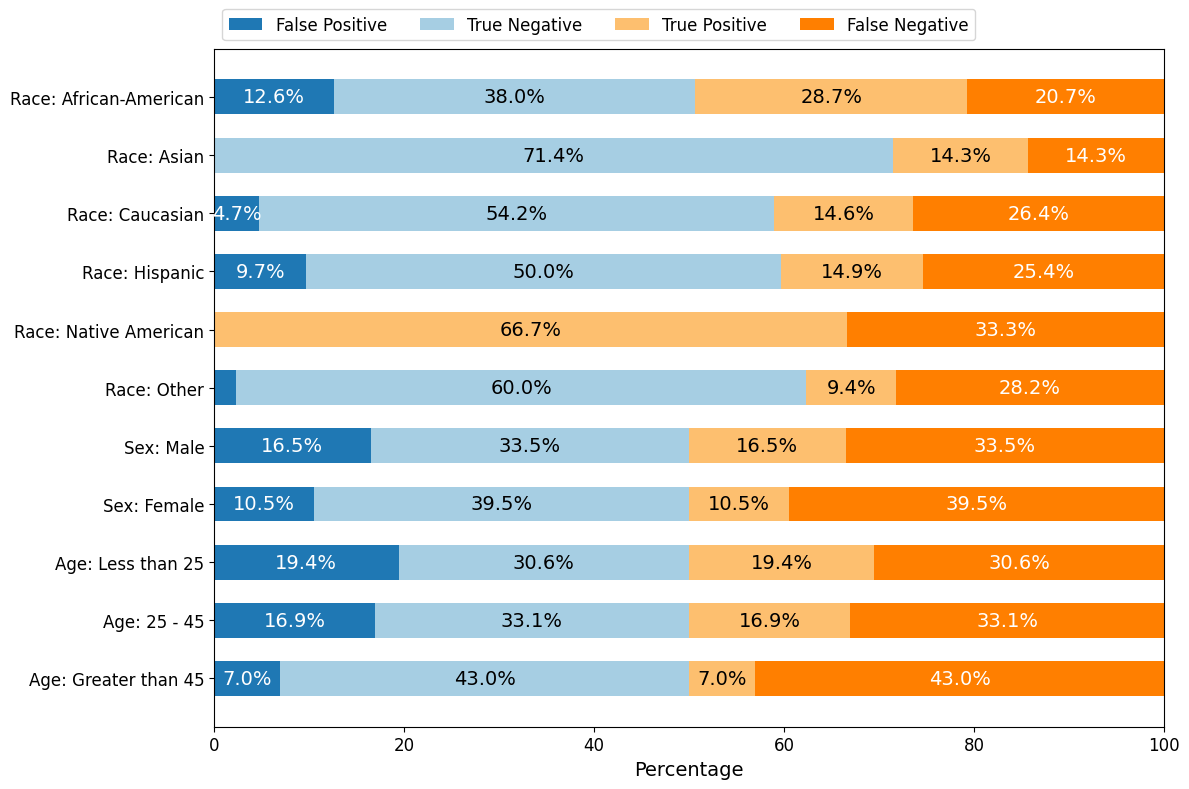

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import colorsys

labels = list(TFPN_counts.keys())
data = np.array(list(TFPN_counts.values()), dtype=float)

row_totals = data.sum(axis=1, keepdims=True)
data = np.divide(data * 100, row_totals, out=np.zeros_like(data), where=row_totals != 0)

data_cum = data.cumsum(axis=1)
category_colors = plt.colormaps["Paired"].colors
category_colors = [category_colors[i] for i in [1, 0, 6, 7]]

fig, ax = plt.subplots(figsize=(12, 8))
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage", fontsize=14)
ax.set_xticks(np.arange(0, 101, 20))
ax.tick_params(axis="both", labelsize=12)

for i, (colname, color) in enumerate(zip(TFPN_names, category_colors)):
    widths = data[:, i]
    starts = data_cum[:, i] - widths
    rects = ax.barh(labels, widths, left=starts, height=0.6,
                    label=colname, color=color)
    bar_labels = [f"{width:.1f}%" if width >= 4 else "" for width in widths]
    
    r, g, b = color
    text_color = "white" if colorsys.rgb_to_hls(r, g, b)[1] <= 0.5 else "black"
    ax.bar_label(rects, labels=bar_labels, label_type="center",
                 color=text_color, fontsize=14)

ax.legend(ncol=len(TFPN_names), bbox_to_anchor=(0, 1),
          loc="lower left", fontsize=12)
fig.tight_layout()
plt.show()

In [53]:
#import sqlite3
#compas = sqlite3.connect("compas.db")
#cursor = compas.cursor()
#cursor.execute(""" 
#    CREATE TABLE IF NOT EXISTS compas_data (
#        id INTEGER PRIMARY KEY,
#        sex TEXT NOT NULL CHECK (sex IN ('Male', 'Female')),
#        race TEXT NOT NULL CHECK (race IN ('African-American', 'Asian', 'Caucasian', 'Hispanic', 'Native American', 'Other')),
#        age INTEGER NOT NULL CHECK (age >= 0)
#    ) STRICT;
#""")
#compas.close()